# Localisation des hôpitaux (ville, département, région d'appartenance)

OBJECTIF : 
L'objectif est de transformer les coordonnées géographiques relatives aux hôpitaux en ville d'appartenance, département d'appartenance et région d'appartenance.
Pour cela, nous mobilisons des données géographiques relatives aux établissements hospitaliers ainsi que les contours administratifs des communes françaises.
La méthode repose sur une jointure spatiale réalisée avec la bibliothèque GeoPandas, permettant d'identifier dans quelle commune se situe chaque établissement.

SOURCES ET REFERENCES

- Données hospitalières : data.gouv.fr
- Contours communaux : Cartiflette
- Référence méthodologique : Lino Galiana, *Introduction aux données spatiales avec GeoPandas*.


In [17]:
%pip install requests
%pip install pandas
%pip install geopandas
%pip install --upgrade cartiflette
%pip install duckdb==1.5.5
%pip install ipywidgets #nécessaire pour cartiflette dans les notebooks
%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note

In [18]:
## 1. IMPORTATION DES PACKAGES
# Gestion des fichiers et téléchargement des données
import os
import requests
from pathlib import Path 

# Manipulation des données
import pandas as pd
import geopandas as gpd

# Traitement des données géographiques
from shapely.wkt import loads
from cartiflette import carti_download

#Visualisation des données
import matplotlib.pyplot as plt

Les bibliothèques mobilisées permettent :
- le téléchargement des données depuis Internet ;
- la manipulation et l'organisation des données tabulaires ;
- le traitement des données géographiques ;
- le téléchargement des contours administratifs.

## 2. Importation et exploration des données hospitalières
Les données relatives aux établissements hospitaliers sont téléchargées depuis la plateforme data.gouv.fr.

Une première exploration permet de vérifier la structure de la base, les variables disponibles et la qualité des informations de localisation.

In [3]:
#Fonction de téléchargement
def telecharger(url, chemin):
    """Télécharge url et l'enregistre dans chemin (sans retélécharger si le fichier existe)."""
    if os.path.exists(chemin):
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    reponse = requests.get(url, timeout=60)
    reponse.raise_for_status()                 # erreur claire si le lien est mort
    with open(chemin, "wb") as f:
        f.write(reponse.content)

In [4]:
#Téléchargement et lecture
URL_APL = "https://www.data.gouv.fr/api/1/datasets/r/c41a1919-fbd7-4d19-a8df-1719bef8b14a"
telecharger(URL_APL, "data/raw/hospitals_point.csv")

df = pd.read_csv("data/raw/hospitals_point.csv")
df

,FID,osm_id,amenity,name,short_name,official_name,alt_name,old_name,operator,operator-type,...,description,opening_hours,source,note,osm_type,osm_version,osm_timestamp,healthcare-speciality,the_geom,osm_original_geom
0,hospitals_point.199789928,199789928,hospital,Établissement Public de Santé de Fresnes,EPSNF,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,extraction vectorielle v1 cadastre-dgi-fr sour...,Prison Hôpital,way,2,2020-06-09T10:14:16Z,NaN,POINT (258310.14044964363 6235141.052489291),SRID=3857;POLYGON((258275.23376428554 6235067....
1,hospitals_point.575489561,575489561,hospital,Centre Hospitalier du Penthièvre & du Poudouvre,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,way,6,2026-05-20T08:45:54Z,NaN,POINT (-324498.6131004042 6174952.219867987),SRID=3857;POLYGON((-324714.2458295185 6174891....
2,hospitals_point.782668290,782668290,hospital,Clinique Pech du Soleil,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,INSEE - 2026-05,NaN,way,3,2026-05-27T16:35:31Z,NaN,POINT (361639.85189134383 5367943.485850866),SRID=3857;POLYGON((361575.2127810663 5367959.6...
3,hospitals_point.38072526,38072526,hospital,Hôpital Bichat-Claude Bernard,NaN,NaN,Hopital Xavier Bichat,NaN,Assistance publique - Hôpitaux de Paris,public,...,NaN,NaN,NaN,NaN,way,18,2023-10-13T14:15:47Z,intensive,POINT (259592.22219624888 6257717.90984779),SRID=3857;POLYGON((259309.3250420606 6257581.0...
4,hospitals_point.106491473,106491473,hospital,Unité de Santé Mentale pour Adultes,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,cadastre-dgi-fr source : Direction Générale de...,NaN,way,4,2019-12-23T23:21:24Z,NaN,POINT (209790.92290423455 6613791.652966853),SRID=3857;POLYGON((209736.71864513436 6613827....
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2501,hospitals_point.1075425737,1075425737,hospital,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,way,2,2024-08-23T11:01:06Z,NaN,POINT (-125955.87209774728 5582755.398745799),SRID=3857;POLYGON((-125975.70363162518 5582751...
2502,hospitals_point.283415613,283415613,hospital,Clinique Rougemont,NaN,NaN,NaN,NaN,Inicea,NaN,...,NaN,Mo-Su 09:00-18:00,cadastre-dgi-fr source : Direction Générale de...,NaN,way,14,2026-08-11T10:22:07Z,physiatry,POINT (17391.457057163512 6110212.548394944),SRID=3857;POLYGON((17337.287114362203 6110237....
2503,hospitals_point.699215560,699215560,hospital,Clinique de l'Étang de l'Olivier,NaN,NaN,Clinique privée d'Istres,NaN,Almaviva Santé,private,...,NaN,NaN,NaN,NaN,way,1,2019-06-23T13:34:31Z,NaN,POINT (555714.7492888186 5389626.65922673),SRID=3857;POLYGON((555590.60256799 5389634.877...
2504,hospitals_point.226685761,226685761,hospital,Institut Paoli-Calmettes,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,way,18,2026-06-29T14:47:45Z,intensive,POINT (602228.8049932518 5351990.283724458),SRID=3857;POLYGON((601792.477047594 5351872.06...


Nous utiliserons la colonne the_geom pour localiser les hôpitaux. On constate qu'il y a beaucoup de variables intéressantes, qui ne sont toutefois pas toujours parfaitement renseignées. Nous allons voir que c'est notamment le cas de la vairable public/privé (operator type).

In [5]:
#Exploration

#Vérification des valeurs manquantes pour l'appartenance au public ou au privé : 
print("Pourcentage de NA public/privé :", df['operator-type'].isna().mean() * 100)
#L'information n'est pas renseignée pour prêt de 65% des hôpitaux

#Par contre d'autres informations sont systématiquement remplies, c'est le cas de la localisation, l'information qui nous intéresse : 
print("Pourcentage de NA localisation :", df['the_geom'].isna().mean() * 100)


Pourcentage de NA public/privé : 64.44533120510773
Pourcentage de NA localisation : 0.0


## 3. Transformation du tableau en GeoDataFrame

Les coordonnées géographiques des établissements sont initialement stockées sous forme de chaînes de caractères au format WKT.

La fonction `loads` de Shapely permet de convertir ces chaînes en objets géométriques interprétables par GeoPandas.

Le système de coordonnées initial est identifié comme étant le Web Mercator (EPSG:3857). Cela a été déterminé en comparant les coordonnées d'hôpitaux dont on connaissait la géolocalisation et en trouvant la projection correspondante. L'usage de EPSG 3857 est fréquent pour les données WEB. Les données sont ensuite reprojetées en EPSG:4326 pour correspondre au système utilisé par Cartiflette.

In [6]:
# Conversion des coordonnées WKT en géométries
df['geometry'] = df['the_geom'].apply(loads)

# Création du GeoDataFrame
gdf_points = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:3857")

# Conversion en EPSG:4326
gdf_points = gdf_points.to_crs("EPSG:4326")

# Vérification
print(gdf_points.crs) #affiche les coordonnées de référence utilisées
display(gdf_points[['name','the_geom', 'geometry']].head(3))
print(gdf_points.geometry.name) #on vérifie que c'est bien la colonne geometry qui sera utilisée

EPSG:4326


,name,the_geom,geometry
0,Établissement Public de Santé de Fresnes,POINT (258310.14044964363 6235141.052489291),POINT (2.32044 48.76536)
1,Centre Hospitalier du Penthièvre & du Poudouvre,POINT (-324498.6131004042 6174952.219867987),POINT (-2.91502 48.4077)
2,Clinique Pech du Soleil,POINT (361639.85189134383 5367943.485850866),POINT (3.24867 43.36663)


geometry


## 4. Importation des contours géographiques des communes

Afin d'identifier la commune d'appartenance de chaque établissement, nous téléchargeons les contours géographiques des communes françaises
à partir de la bibliothèque Cartiflette.

Les données correspondent au découpage administratif de 2022 et couvrent la France entière, y compris les DROM rapprochés. Cela dit, et c'est précisé sur la page web de la base de données, seuls les hôpitaux en France métropolitaine sont recensés dans la base.

In [7]:
# Téléchargement de la France entière (via Cartiflette)
communes_borders = carti_download(
    crs=4326,
    values="France",
    borders="COMMUNE",
    vectorfile_format="geojson",
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2022
)

## 5. Jointure spatiale entre les hôpitaux et les communes

Une jointure spatiale est réalisée entre les établissements hospitaliers (information venant de data.gouv) et les contours des communes (cartiflette).

La méthode `sjoin` permet d'associer chaque établissement à la commune dans laquelle se situe son point géographique.

Le prédicat `within` permet de vérifier que le point représentant l'établissement est situé à l'intérieur du polygone communal.

L'option `how="left"` permet de conserver l'ensemble des établissements, y compris ceux pour lesquels aucune commune n'a été identifiée. (la commune est alors indiquée NA).

In [8]:
resultat = gpd.sjoin(gdf_points, communes_borders, how="left", predicate="within") 

display(resultat)

,FID,osm_id,amenity,name,short_name,official_name,alt_name,old_name,operator,operator-type,...,TDUU2017,AAV2020,TAAV2017,TDAAV2017,CATEAAV2020,BV2012,LIBELLE_DEPARTEMENT,LIBELLE_REGION,PAYS,SOURCE
0,hospitals_point.199789928,199789928,hospital,Établissement Public de Santé de Fresnes,EPSNF,NaN,NaN,NaN,NaN,NaN,...,80.0,001,5.0,50.0,12.0,75056,Val-de-Marne,Île-de-France,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
1,hospitals_point.575489561,575489561,hospital,Centre Hospitalier du Penthièvre & du Poudouvre,NaN,NaN,NaN,NaN,NaN,NaN,...,12.0,056,3.0,31.0,20.0,22262,Côtes-d'Armor,Bretagne,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
2,hospitals_point.782668290,782668290,hospital,Clinique Pech du Soleil,NaN,NaN,NaN,NaN,NaN,NaN,...,52.0,060,2.0,25.0,20.0,34032,Hérault,Occitanie,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
3,hospitals_point.38072526,38072526,hospital,Hôpital Bichat-Claude Bernard,NaN,NaN,Hopital Xavier Bichat,NaN,Assistance publique - Hôpitaux de Paris,public,...,80.0,001,5.0,50.0,11.0,75056,Paris,Île-de-France,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
4,hospitals_point.106491473,106491473,hospital,Unité de Santé Mentale pour Adultes,NaN,NaN,NaN,NaN,NaN,NaN,...,52.0,073,2.0,25.0,11.0,62193,Pas-de-Calais,Hauts-de-France,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2501,hospitals_point.1075425737,1075425737,hospital,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,21.0,006,4.0,42.0,20.0,33011,Gironde,Nouvelle-Aquitaine,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
2502,hospitals_point.283415613,283415613,hospital,Clinique Rougemont,NaN,NaN,NaN,NaN,Inicea,NaN,...,71.0,034,3.0,32.0,11.0,72181,Sarthe,Pays de la Loire,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
2503,hospitals_point.699215560,699215560,hospital,Clinique de l'Étang de l'Olivier,NaN,NaN,Clinique privée d'Istres,NaN,Almaviva Santé,private,...,73.0,003,4.0,42.0,20.0,13055,Bouches-du-Rhône,Provence-Alpes-Côte d'Azur,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE
2504,hospitals_point.226685761,226685761,hospital,Institut Paoli-Calmettes,NaN,NaN,NaN,NaN,NaN,NaN,...,73.0,003,4.0,42.0,11.0,13055,Bouches-du-Rhône,Provence-Alpes-Côte d'Azur,France,IGN:EXPRESS-COG-CARTO-TERRITOIRE


## 6. Nettoyage et harmonisation des variables géographiques

Après la jointure spatiale, plusieurs opérations sont nécessaires
pour harmoniser les informations géographiques obtenues.

Il s'agit notamment :
- de renommer certaines variables pour faciliter les jointures futures ;
- d'harmoniser les formats des codes INSEE ;
- de traiter les valeurs manquantes.

In [9]:
# A - Récupération du nom de la région
resultat['NOM_REGIO'] = resultat['LIBELLE_REGION']

# B - Renommage du code INSEE communal
resultat = resultat.rename(
    columns={'INSEE_COM': 'COM_INSEE'}
)

display(resultat[['name','NOM_REGIO', 'INSEE_REG', 'COM_INSEE']].sample(10))

,name,NOM_REGIO,INSEE_REG,COM_INSEE
497,Clinique Joncs Marins,Île-de-France,11.0,94058
888,CRP Saint-Brieuc - Fondation St Jean de Dieu,Bretagne,53.0,22278
126,Hôpital Garonne,Occitanie,76.0,31555
727,Polyclinique,Normandie,28.0,14366
2088,Centre hospitalier des Pays de Morlaix,Bretagne,53.0,29151
1206,Centre hospitalier intercommunal Meulan-Les Mu...,Île-de-France,11.0,78440
1821,Clinique Ker Yonnec,Bourgogne-Franche-Comté,27.0,89074
1767,51-MSG-RDC-NORD,Bretagne,53.0,35360
188,Centre Hospitalier Marguerite de Lorraine,Normandie,28.0,61293
2050,Centre SAMU/SMUR et CESU 67,Grand Est,44.0,67482


In [10]:
#Harmonisation des codes INSEE (remplace les NaN par une chaîne vide '', sinon formate sur 5 chiffres)
com_numeric = pd.to_numeric(resultat['COM_INSEE'], errors='coerce')
resultat['COM_INSEE'] = com_numeric.dropna().astype(int).astype(str).str.zfill(5)
resultat['COM_INSEE'] = resultat['COM_INSEE'].fillna('')

#Harmonisation des codes départements 
dep_numeric = pd.to_numeric(resultat['INSEE_DEP'], errors='coerce')
resultat['INSEE_DEP'] = dep_numeric.dropna().astype(int).astype(str).str.zfill(2)
resultat['INSEE_DEP'] = resultat['INSEE_DEP'].fillna('')


In [11]:
#Affichage des résultats 

display(resultat[['name', 'the_geom', 'NOM_REGIO', 'INSEE_DEP', 'COM_INSEE']])
print("Pourcentage de NA commune insee :", resultat['COM_INSEE'].isna().mean() * 100)
print("Nombre hôpitaux NA commune :", resultat['COM_INSEE'].isna().sum())

,name,the_geom,NOM_REGIO,INSEE_DEP,COM_INSEE
0,Établissement Public de Santé de Fresnes,POINT (258310.14044964363 6235141.052489291),Île-de-France,94,94034
1,Centre Hospitalier du Penthièvre & du Poudouvre,POINT (-324498.6131004042 6174952.219867987),Bretagne,22,22262
2,Clinique Pech du Soleil,POINT (361639.85189134383 5367943.485850866),Occitanie,34,34037
3,Hôpital Bichat-Claude Bernard,POINT (259592.22219624888 6257717.90984779),Île-de-France,75,75056
4,Unité de Santé Mentale pour Adultes,POINT (209790.92290423455 6613791.652966853),Hauts-de-France,62,62193
...,...,...,...,...,...
2501,NaN,POINT (-125955.87209774728 5582755.398745799),Nouvelle-Aquitaine,33,33011
2502,Clinique Rougemont,POINT (17391.457057163512 6110212.548394944),Pays de la Loire,72,72181
2503,Clinique de l'Étang de l'Olivier,POINT (555714.7492888186 5389626.65922673),Provence-Alpes-Côte d'Azur,13,13047
2504,Institut Paoli-Calmettes,POINT (602228.8049932518 5351990.283724458),Provence-Alpes-Côte d'Azur,13,13055


Pourcentage de NA commune insee : 0.0
Nombre hôpitaux NA commune : 0


On a toujours bien 2506 lignes, il n'y a pas eu d'attrition.

## 7. Exportation de la base de données finale

Une version synthétique de la base est exportée au format CSV.

Elle conserve les principales informations relatives à l'identification des établissements ainsi que leur localisation administrative.

In [21]:
RACINE = Path.cwd()
resultat.to_csv(RACINE / "data/processed/BASE_loc_hopitaux.csv", columns=['name', 'geometry', 'INSEE_DEP', 'COM_INSEE', 'NOM', 'STATUT', 'POPULATION', 'AREA','NOM_REGIO'], encoding='utf-8')

## 8. Répartition des établissements hospitaliers par région

À partir de la base enrichie, nous pouvons réaliser une première analyse descriptive de la répartition géographique des établissements.

Cette étape consiste à calculer le nombre d'établissements identifiés dans chaque région ainsi que leur part dans l'ensemble des établissements.

In [14]:
# Calcul du nombre d'hôpitaux par région
counts = resultat['NOM_REGIO'].value_counts()

# Calcul des pourcentages
percentages = (
    resultat['NOM_REGIO'].value_counts(normalize=True) * 100
)

# Création du tableau récapitulatif
classement_regions = pd.DataFrame({
    'Nombre': counts,
    'Pourcentage (%)': percentages.round(2)
})

display(classement_regions)

,Nombre,Pourcentage (%)
NOM_REGIO,,
Île-de-France,348,13.96
Auvergne-Rhône-Alpes,318,12.76
Occitanie,292,11.72
Nouvelle-Aquitaine,239,9.59
Grand Est,215,8.63
Hauts-de-France,213,8.55
Provence-Alpes-Côte d'Azur,183,7.34
Bretagne,166,6.66
Normandie,158,6.34


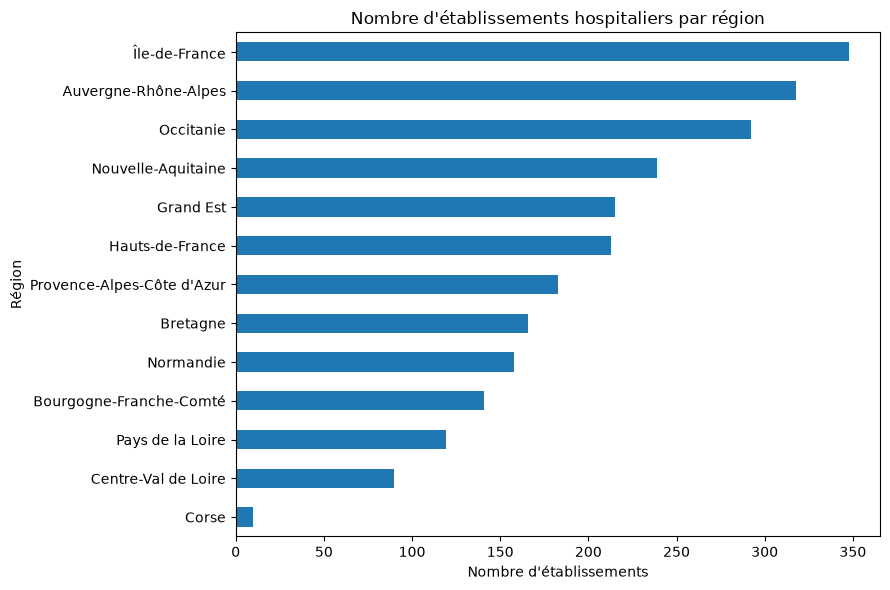

In [ ]:
classement_regions['Nombre'].sort_values().plot(
    kind='barh',
    figsize=(9, 6),
    title="Nombre d'établissements hospitaliers par région"
)

plt.xlabel("Nombre d'établissements")
plt.ylabel("Région")
plt.tight_layout()
plt.show()

#Il faudrait croiser ça avec la population

## 9. Conclusion et limites

La jointure spatiale a permis d'enrichir la base de données hospitalières avec des informations relatives à leur localisation administrative : commune, département et région.

La totalité des établissements ont pu être associés à une commune. 

Le découpage administratif retenu correspond à celui de 2022. 

L'absence des territoires ultramarins est une autre grande limite de ces données.